In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pasta onde ficam as figuras usadas no relatório
os.makedirs("../markdown/figuras_used_cars", exist_ok=True)

# 1. Análise Exploratória dos dados (EDA)

In [2]:
dados = pd.read_csv("../../data/used_cars.csv")

print("Forma do dataframe: ", dados.shape)
dados.head()

Forma do dataframe:  (20063, 10)


,price,trim,isOneOwner,mileage,year,color,fuel,soundSystem,wheelType,displacement
0,2.988,Other,No,193.296,1995,Black,Gasoline,unsp,Alloy,3.2
1,6.595,Other,No,129.948,1995,Other,Gasoline,Premium,Alloy,3.2
2,7.993,Other,No,140.428,1997,White,Gasoline,Bose,Alloy,3.2
3,5.995,Other,No,113.622,1999,Silver,Gasoline,unsp,Alloy,4.2
4,3.000,Other,No,167.673,1999,Silver,Gasoline,unsp,Alloy,4.2


In [3]:
print("Tipo dos dados:\n")
print(dados.dtypes)

print("\nValores faltantes:", dados.isna().sum().sum())
print("Linhas duplicadas:", dados.duplicated().sum())

Tipo dos dados:

price           float64
trim                str
isOneOwner          str
mileage         float64
year              int64
color               str
fuel                str
soundSystem         str
wheelType           str
displacement    float64
dtype: object

Valores faltantes: 0
Linhas duplicadas: 15


In [4]:
dados.describe()

,price,mileage,year,displacement
count,20063.000000,20063.000000,20063.000000,20063.000000
mean,30.747244,73.113479,2007.010018,5.058964
std,18.291085,43.075537,4.128162,0.628131
min,0.599000,0.008000,1994.000000,3.000000
25%,13.495000,39.888500,2004.000000,4.600000
50%,29.454000,67.187000,2007.000000,5.500000
75%,43.995000,98.213000,2010.000000,5.500000
max,79.999000,488.525000,2014.000000,6.300000


In [5]:
colunas_categoricas = ["trim", "isOneOwner", "color", "fuel", "soundSystem", "wheelType"]

for col in colunas_categoricas:
    print(f"{col}:", dados[col].value_counts().to_dict())

trim: {'550': 11825, 'Other': 2790, '430': 2787, '500': 2661}
isOneOwner: {'No': 16594, 'Yes': 3469}
color: {'Black': 8194, 'Other': 4875, 'Silver': 4353, 'White': 2641}
fuel: {'Gasoline': 19632, 'Hybrid': 220, 'Diesel': 211}
soundSystem: {'unsp': 9100, 'Premium': 5320, 'Harman Kardon': 4278, 'Bose': 1261, 'Bang Olufsen': 104}
wheelType: {'Alloy': 11111, 'unsp': 8404, 'Premium': 428, 'other': 120}


## 1.1 Distribuição do preço (`price`)

Média:          30.75
Mediana:        29.45
Desvio padrão:  18.29
Skewness:       0.39
Mínimo e máximo: 0.60 e 80.00
Carros com price acima de 70: 314 (1.6%)


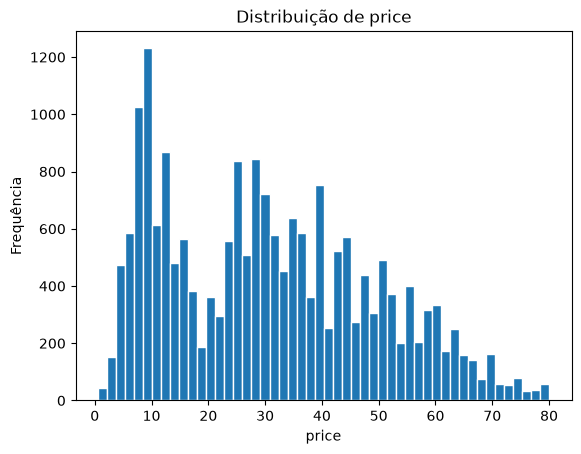

In [6]:
preco = dados["price"]

print(f"Média:          {preco.mean():.2f}")
print(f"Mediana:        {preco.median():.2f}")
print(f"Desvio padrão:  {preco.std():.2f}")
print(f"Skewness:       {preco.skew():.2f}")
print(f"Mínimo e máximo: {preco.min():.2f} e {preco.max():.2f}")

# Poucos carros ficam nas faixas de preço mais altas
print(f"Carros com price acima de 70: {(preco > 70).sum()} ({(preco > 70).mean() * 100:.1f}%)")

plt.hist(preco, bins=50, edgecolor="white")
plt.xlabel("price")
plt.ylabel("Frequência")
plt.title("Distribuição de price")

plt.savefig("../markdown/figuras_used_cars/01_hist_price.png", dpi=150, bbox_inches="tight")
plt.show()

## 1.2 Relação do preço com as variáveis numéricas

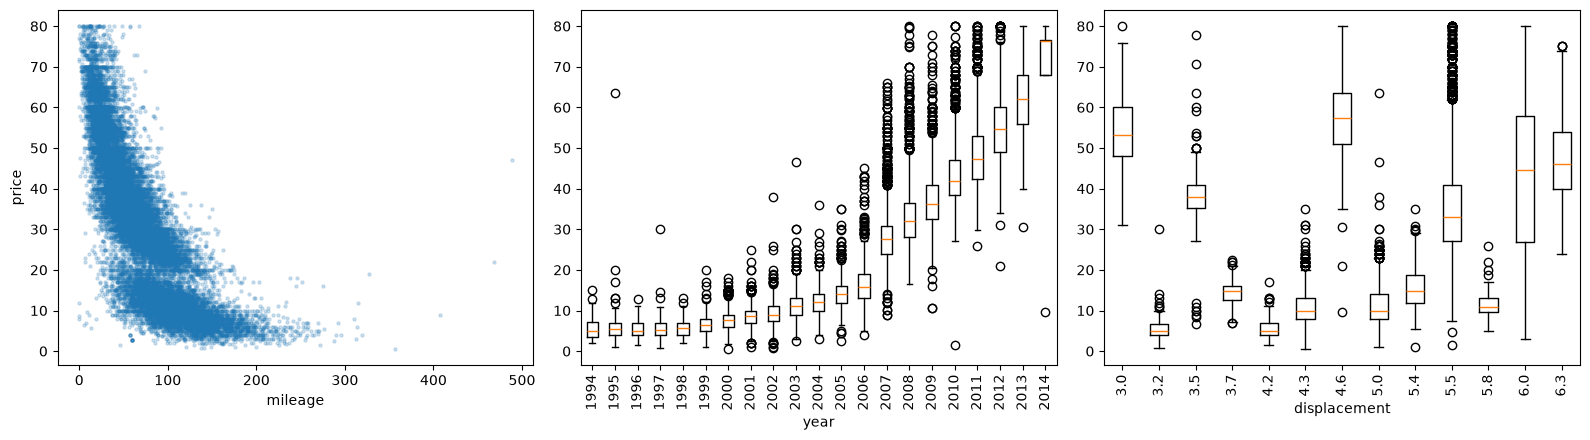

Correlação com price:
mileage        -0.795
year            0.882
displacement    0.203
dtype: float64


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# mileage é contínua: dispersão
axes[0].scatter(dados["mileage"], dados["price"], s=5, alpha=0.2)
axes[0].set_xlabel("mileage")

# year e displacement têm poucos valores distintos: um box plot para cada valor
for ax, col in zip(axes[1:], ["year", "displacement"]):
    valores = sorted(dados[col].unique())
    ax.boxplot([dados.loc[dados[col] == v, "price"] for v in valores], tick_labels=valores)
    ax.tick_params(axis="x", rotation=90)
    ax.set_xlabel(col)

axes[0].set_ylabel("price")

plt.tight_layout()
plt.savefig("../markdown/figuras_used_cars/02_price_vs_numericas.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlação com price:")
print(dados[["mileage", "year", "displacement"]].corrwith(dados["price"]).round(3))

## 1.3 Relação do preço com as variáveis categóricas

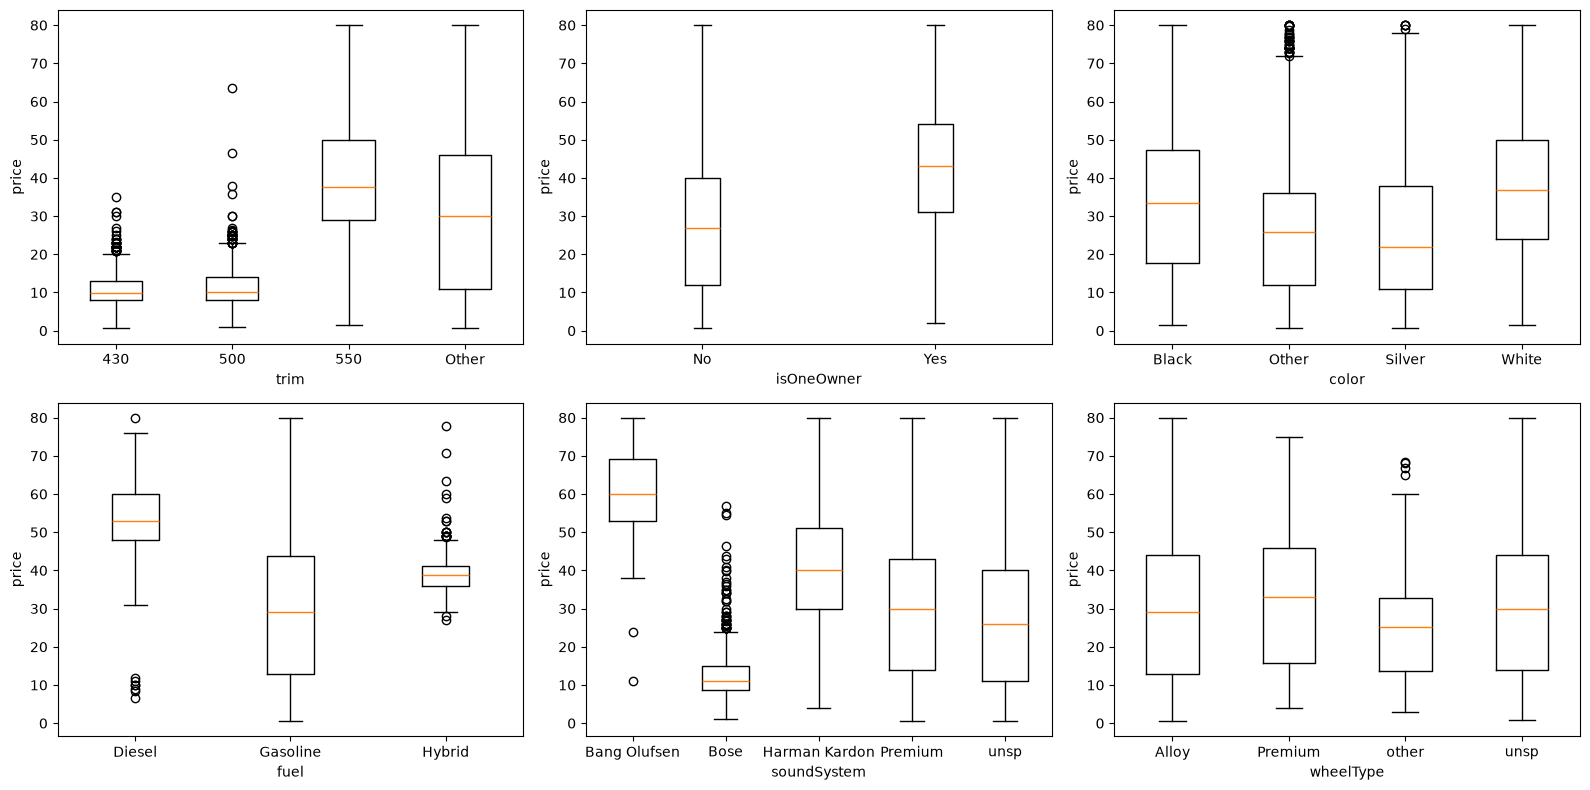

Mediana de price por trim:
trim
430       9.99
500      10.00
550      37.50
Other    30.00 

Mediana de price por isOneOwner:
isOneOwner
No     26.98
Yes    42.99 

Mediana de price por color:
color
Black     33.50
Other     25.89
Silver    22.00
White     36.80 

Mediana de price por fuel:
fuel
Diesel      53.00
Gasoline    28.99
Hybrid      38.90 

Mediana de price por soundSystem:
soundSystem
Bang Olufsen     59.94
Bose             11.00
Harman Kardon    39.99
Premium          29.77
unsp             25.95 

Mediana de price por wheelType:
wheelType
Alloy      28.99
Premium    32.99
other      25.22
unsp       29.95 



In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, col in zip(axes.ravel(), colunas_categoricas):
    categorias = sorted(dados[col].unique())
    ax.boxplot([dados.loc[dados[col] == c, "price"] for c in categorias], tick_labels=categorias)
    ax.set_xlabel(col)
    ax.set_ylabel("price")

plt.tight_layout()
plt.savefig("../markdown/figuras_used_cars/03_price_vs_categoricas.png", dpi=150, bbox_inches="tight")
plt.show()

for col in colunas_categoricas:
    print(f"Mediana de price por {col}:")
    print(dados.groupby(col)["price"].median().round(2).to_string(), "\n")

# 2. Preparação dos dados

In [9]:
y = dados["price"]

# As variáveis categóricas viram colunas 0/1 (dummies).
# drop_first=True descarta uma categoria de cada variável, para evitar colinearidade perfeita
X = pd.get_dummies(dados.drop(columns=["price"]), columns=colunas_categoricas, drop_first=True, dtype=int)

print("Formato de X:", X.shape)
X.head()

Formato de X: (20063, 19)


,mileage,year,displacement,trim_500,trim_550,trim_Other,isOneOwner_Yes,color_Other,color_Silver,color_White,fuel_Gasoline,fuel_Hybrid,soundSystem_Bose,soundSystem_Harman Kardon,soundSystem_Premium,soundSystem_unsp,wheelType_Premium,wheelType_other,wheelType_unsp
0,193.296,1995,3.2,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0
1,129.948,1995,3.2,0,0,1,0,1,0,0,1,0,0,0,1,0,0,0,0
2,140.428,1997,3.2,0,0,1,0,0,0,1,1,0,1,0,0,0,0,0,0
3,113.622,1999,4.2,0,0,1,0,0,1,0,1,0,0,0,0,1,0,0,0
4,167.673,1999,4.2,0,0,1,0,0,1,0,1,0,0,0,0,1,0,0,0


In [10]:
from sklearn.model_selection import train_test_split

# Divisão 50/50, estratificada pelo preço: dividimos price em 10 faixas de mesmo tamanho (decis)
# para treino e teste terem a mesma distribuição de preços
faixas_preco = pd.qcut(y, q=10)

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=faixas_preco
)

print("Treino:", X_treino.shape, f"| price médio: {y_treino.mean():.2f}")
print("Teste: ", X_teste.shape, f"| price médio: {y_teste.mean():.2f}")

Treino: (10031, 19) | price médio: 30.75
Teste:  (10032, 19) | price médio: 30.74


# 3. Etapa de Treino

## 3.1 Regressão Linear Múltipla

In [11]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_treino, y_treino)

coeficientes = pd.Series(linear_model.coef_, index=X.columns)
print("Intercepto:", round(linear_model.intercept_, 2))
coeficientes.round(3)

Intercepto: -5744.17


mileage                      -0.124
year                          2.886
displacement                 -2.490
trim_500                      3.954
trim_550                      5.145
trim_Other                   11.949
isOneOwner_Yes                0.756
color_Other                  -1.278
color_Silver                 -1.328
color_White                   1.805
fuel_Gasoline                10.052
fuel_Hybrid                  -5.910
soundSystem_Bose            -12.063
soundSystem_Harman Kardon    -9.166
soundSystem_Premium          -9.740
soundSystem_unsp             -9.441
wheelType_Premium             0.591
wheelType_other              -1.448
wheelType_unsp                0.165
dtype: float64

## 3.2 Árvore de regressão

In [12]:
from sklearn.tree import DecisionTreeRegressor

# Árvore sem limite de crescimento (só para ver o que acontece)
arvore_cheia = DecisionTreeRegressor(random_state=42)
arvore_cheia.fit(X_treino, y_treino)

print("Profundidade:", arvore_cheia.get_depth())
print("Folhas:", arvore_cheia.get_n_leaves())

Profundidade: 33
Folhas: 9898


A árvore sem limite cresce até quase uma folha por carro. Para controlar o sobreajuste, escolhemos o **número mínimo de observações por folha** com validação cruzada (5 partes) **usando só o treino**, pelo RMSE.

In [13]:
from sklearn.model_selection import GridSearchCV

busca = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid={"min_samples_leaf": [1, 2, 5, 10, 20, 50, 100]},
    scoring="neg_root_mean_squared_error",
    cv=5,
)
busca.fit(X_treino, y_treino)

print("Melhor min_samples_leaf:", busca.best_params_["min_samples_leaf"])
print(f"RMSE na validação cruzada: {-busca.best_score_:.3f}")

tree_model = busca.best_estimator_
print("Folhas da árvore escolhida:", tree_model.get_n_leaves())

Melhor min_samples_leaf: 20
RMSE na validação cruzada: 4.793
Folhas da árvore escolhida: 380


## 3.3 Random Forest

In [14]:
from sklearn.ensemble import RandomForestRegressor

# max_features = 1/3 das variáveis em cada split (recomendação de Breiman para regressão)
forest_model = RandomForestRegressor(n_estimators=500, max_features=1 / 3, random_state=42, n_jobs=-1)
forest_model.fit(X_treino, y_treino)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.3333333333333333
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not pro

## 3.4 Boosting

In [15]:
from sklearn.ensemble import GradientBoostingRegressor

# Hiperparâmetros usuais, fixados antes de olhar o teste
boosting_model = GradientBoostingRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=4, random_state=42
)
boosting_model.fit(X_treino, y_treino)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",500
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

# 4. Etapa de Teste

## 4.1 RMSE de teste e gráficos de previsto vs. observado

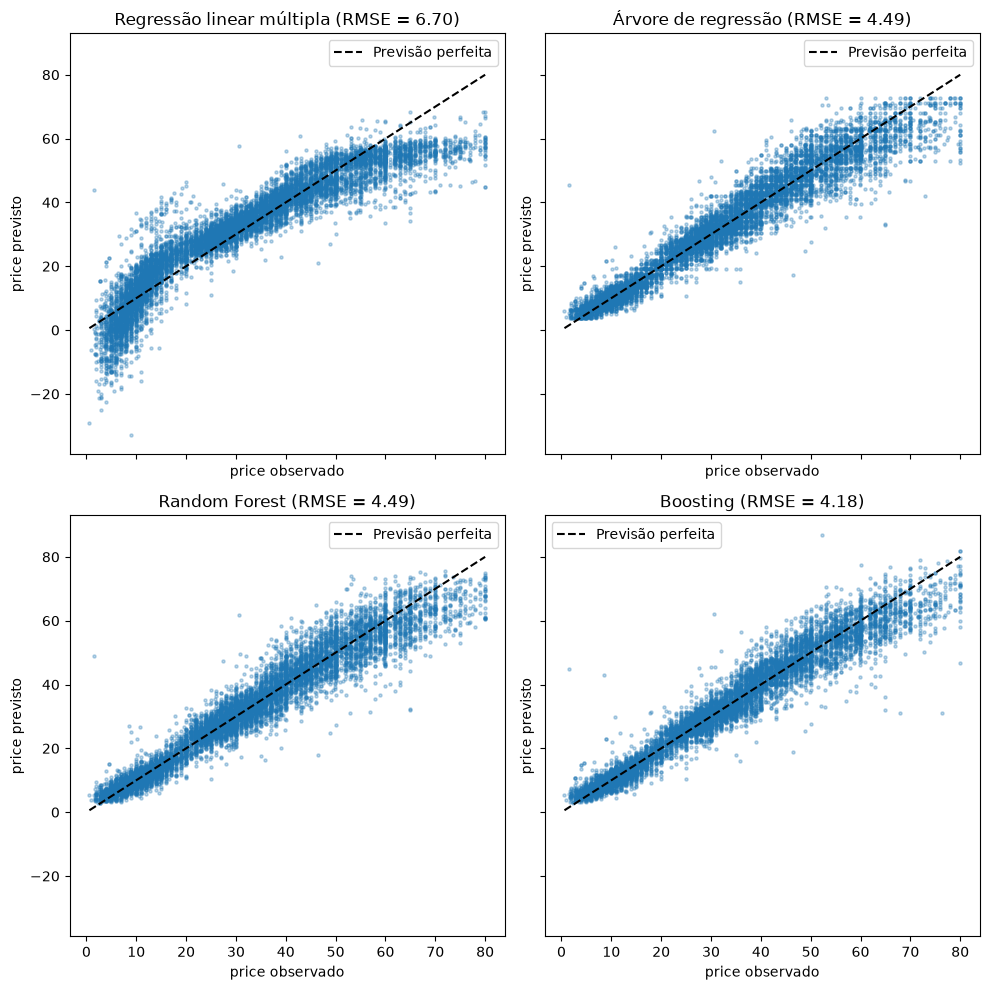

RMSE de prever sempre a média do treino (referência): 18.32



,RMSE teste,MAE teste,R² teste,Previsões negativas
Modelo,,,,
Regressão linear múltipla,6.696,4.982,0.866,444
Árvore de regressão,4.493,3.126,0.940,0
Random Forest,4.485,3.155,0.940,0
Boosting,4.177,2.893,0.948,0


In [16]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

modelos = {
    "Regressão linear múltipla": linear_model,
    "Árvore de regressão": tree_model,
    "Random Forest": forest_model,
    "Boosting": boosting_model,
}

limites = [y_teste.min(), y_teste.max()]
resultados = []

fig, axes = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True)

for ax, (nome, modelo) in zip(axes.ravel(), modelos.items()):
    previsto = modelo.predict(X_teste)
    rmse = root_mean_squared_error(y_teste, previsto)

    ax.scatter(y_teste, previsto, s=5, alpha=0.3)
    ax.plot(limites, limites, "k--", label="Previsão perfeita")
    ax.set_title(f"{nome} (RMSE = {rmse:.2f})")
    ax.set_xlabel("price observado")
    ax.set_ylabel("price previsto")
    ax.legend()

    resultados.append({
        "Modelo": nome,
        "RMSE teste": rmse,
        "MAE teste": mean_absolute_error(y_teste, previsto),
        "R² teste": r2_score(y_teste, previsto),
        "Previsões negativas": int((previsto < 0).sum()),
    })

plt.tight_layout()
plt.savefig("../markdown/figuras_used_cars/04_previsto_observado.png", dpi=150, bbox_inches="tight")
plt.show()

# Referência: prever sempre a média do treino
rmse_media = np.sqrt(((y_teste - y_treino.mean()) ** 2).mean())
print(f"RMSE de prever sempre a média do treino (referência): {rmse_media:.2f}\n")

pd.DataFrame(resultados).set_index("Modelo").round(3)

## 4.2 Árvore sem poda (só para comparação)

In [17]:
previsto_cheia = arvore_cheia.predict(X_teste)

print(f"RMSE de treino: {root_mean_squared_error(y_treino, arvore_cheia.predict(X_treino)):.3f}")
print(f"RMSE de teste:  {root_mean_squared_error(y_teste, previsto_cheia):.3f}")

RMSE de treino: 0.048
RMSE de teste:  5.893


## 4.3 Importância das variáveis na Random Forest

In [18]:
# Importância por redução de impureza, normalizada para somar 1
importancia = pd.Series(forest_model.feature_importances_, index=X.columns)
importancia.sort_values(ascending=False).round(3)

year                         0.424
mileage                      0.307
displacement                 0.101
trim_550                     0.093
trim_500                     0.021
trim_Other                   0.010
soundSystem_Harman Kardon    0.010
isOneOwner_Yes               0.007
fuel_Gasoline                0.006
wheelType_unsp               0.003
color_Other                  0.003
soundSystem_Bose             0.003
color_White                  0.003
color_Silver                 0.002
fuel_Hybrid                  0.002
soundSystem_unsp             0.002
soundSystem_Premium          0.002
wheelType_Premium            0.001
wheelType_other              0.000
dtype: float64